# Un modelo para la tasa de memorización

En este problema estudiamos un modelo muy simple de memorización de listas. Sea $L(t)$ la fracción de la lista que ya memorizamos al tiempo $t$ ($L=0$: no sabemos nada; $L=1$: sabemos toda la lista). La hipótesis es que **la rapidez con la que aprendemos es proporcional a lo que nos falta por aprender**:

$$
\frac{dL}{dt} = \kappa\,(1 - L), \qquad L(0) = 0 .
$$

El parámetro $\kappa>0$ (en $\text{min}^{-1}$) es personal: mide qué tan rápido memoriza cada quien.

**Sobre los datos.** El enunciado pide hacer el experimento con las cuatro listas de números. Aquí, en lugar de datos reales, usamos **datos simulados**: construimos un *participante virtual* cuyo valor de $\kappa$ conocemos y le aplicamos exactamente el mismo protocolo. Esto tiene una ventaja didáctica enorme: como conocemos la respuesta correcta, podemos comprobar si nuestros métodos de estimación la recuperan y qué tan precisos son. Al final discutimos qué cambiaría con datos reales.

**Contenido**

1. Solución analítica del modelo y su interpretación "por número".
2. El participante virtual y la simulación del protocolo.
3. Estimación de $\kappa$ con la lista 1 (dos métodos) y comparación con el modelo.
4. ¿Cuánto tardaríamos en aprender listas de 20 y de 100 números?
5. Listas 2, 3 y 4: ¿$\kappa$ es constante o mejora con la práctica? ¿Cómo modificar el modelo?

## 1. El modelo y su solución

La ecuación es separable. Escribimos $u = 1 - L$, de modo que $du/dt = -dL/dt = -\kappa u$. La solución es $u(t) = u(0)\,e^{-\kappa t}$ y, como $u(0) = 1 - L(0) = 1$,

$$
L(t) = 1 - e^{-\kappa t}.
$$

Algunas consecuencias que usaremos más adelante:

* $L(t)$ crece rápido al principio y cada vez más lento: cuando ya sabemos casi todo, queda poco por aprender.
* $L(t) < 1$ para todo $t$ finito. **El modelo nunca predice que terminemos de aprender la lista**; para responder "¿cuánto tardo en aprenderla?" necesitaremos un criterio adicional (sección 4).
* El tiempo para aprender la mitad de la lista es $t_{1/2} = \ln 2/\kappa$, como en el decaimiento radiactivo.
* Si tomamos logaritmo: $-\ln(1 - L) = \kappa t$. Es decir, la gráfica de $-\ln(1-L)$ contra $t$ es **una recta que pasa por el origen con pendiente** $\kappa$. Esto nos dará un primer método para estimar $\kappa$.

**Una interpretación "por número".** Imaginemos que cada número de la lista, mientras no se ha aprendido, tiene una probabilidad $\kappa\,\Delta t$ de aprenderse en un intervalo corto de tiempo $\Delta t$, de forma independiente de los demás. Entonces el tiempo que tarda en aprenderse cada número es una variable aleatoria exponencial con tasa $\kappa$, y la fracción *esperada* de números aprendidos al tiempo $t$ es exactamente $1 - e^{-\kappa t}$. Es decir, la ecuación diferencial describe el **promedio** de un proceso aleatorio. Esta interpretación es la que usaremos para construir al participante virtual.

In [1]:
# ============================================================
# Bibliotecas que usaremos en todo el notebook
# ============================================================
import numpy as np                    # arreglos numéricos y funciones matemáticas
import matplotlib.pyplot as plt       # gráficas
from scipy.optimize import curve_fit  # ajuste de curvas por mínimos cuadrados

# Estilo de las gráficas: letra legible y una rejilla tenue.
plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Generador de números aleatorios con SEMILLA FIJA.
# Gracias a la semilla, cada vez que se ejecute el notebook se obtienen
# exactamente los mismos "datos simulados", y los resultados son reproducibles.
rng = np.random.default_rng(seed=2026)

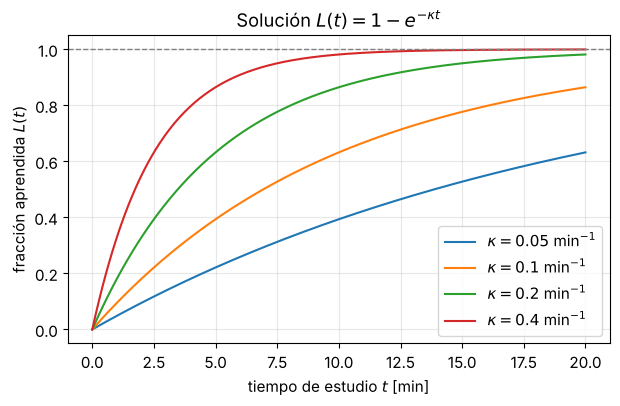

In [2]:
# ============================================================
# Solución analítica del modelo dL/dt = kappa (1 - L), con L(0) = 0
# ============================================================
def L_modelo(t, kappa):
    """
    Fracción de la lista aprendida al tiempo t según el modelo.

    Parámetros
    ----------
    t : float o arreglo
        Tiempo de estudio acumulado (en minutos).
    kappa : float
        Tasa personal de memorización (en 1/min).

    Regresa
    -------
    float o arreglo con L(t) = 1 - exp(-kappa t).
    """
    return 1.0 - np.exp(-kappa * t)


# Graficamos la solución para varios valores de kappa para ver su efecto.
t = np.linspace(0, 20, 300)          # 300 tiempos entre 0 y 20 minutos
fig, ax = plt.subplots(figsize=(7, 4))
for kappa in [0.05, 0.1, 0.2, 0.4]:
    ax.plot(t, L_modelo(t, kappa), label=rf"$\kappa = {kappa}$ min$^{{-1}}$")
ax.axhline(1, color="gray", ls="--", lw=1)   # la asíntota L = 1
ax.set_xlabel("tiempo de estudio $t$ [min]")
ax.set_ylabel("fracción aprendida $L(t)$")
ax.set_title(r"Solución $L(t) = 1 - e^{-\kappa t}$")
ax.legend()
plt.show()

## 2. El participante virtual

El protocolo del enunciado es: estudiar la lista un minuto, escribir los números que recordamos en el orden correcto (dejando huecos), estudiar otro minuto, volver a escribir... diez veces. Al final calificamos cada prueba comparando **posición por posición** con la lista original.

Nuestro participante virtual sigue estas reglas (esta es la "verdad oculta" que el análisis no conoce):

1. **Aprendizaje.** Durante cada minuto de estudio, cada número que todavía no se ha aprendido se aprende con probabilidad $p = 1 - e^{-\kappa\cdot 1\,\text{min}}$. Es la versión en pasos de un minuto de la interpretación "por número" de la sección 1, así que el número de minutos que tarda en aprenderse cada número sigue una distribución **geométrica** con parámetro $p$.
2. **Sin olvido.** Lo aprendido no se olvida (igual que en el modelo).
3. **Lapsus.** En cada prueba, un número aprendido se escribe mal (por ejemplo, con un dígito cambiado) con probabilidad $\varepsilon = 0.03$. Esto **no** está en el modelo; lo incluimos para que los datos tengan algo de ruido "realista" que el modelo no explica.
4. **Práctica.** Su $\kappa$ mejora un poco de una lista a la siguiente. Para la lista $j$:

$$
\kappa_j = \kappa_{\max} - (\kappa_{\max} - \kappa_0)\, e^{-(j-1)/\tau},
\qquad \kappa_0 = 0.15,\quad \kappa_{\max} = 0.30,\quad \tau = 2 .
$$

Durante el análisis (secciones 3 a 5) haremos como si no conociéramos estos valores. Solo los usaremos al final para evaluar qué tan bien los recuperamos.

In [3]:
# ============================================================
# Las cuatro listas del enunciado (20 números de tres dígitos cada una)
# ============================================================
LISTAS = {
    1: [482, 812, 311, 993, 705, 470, 297, 499, 461, 934,
        683, 872, 118, 952, 333, 229, 980, 275, 843, 244],
    2: [145, 909, 969, 206, 532, 507, 232, 536, 281, 534,
        391, 332, 270, 442, 683, 812, 718, 960, 145, 721],
    3: [793, 506, 687, 839, 503, 541, 477, 348, 851, 130,
        462, 605, 678, 888, 990, 779, 453, 752, 536, 300],
    4: [799, 326, 604, 505, 498, 532, 161, 607, 869, 330,
        644, 303, 328, 403, 787, 290, 474, 355, 804, 550],
}
N_ITEMS = 20       # números por lista
N_RONDAS = 10      # rondas de "estudiar 1 minuto + prueba"
DT = 1.0           # minutos de estudio por ronda
PROB_LAPSUS = 0.03 # probabilidad de escribir mal un número ya aprendido

# -----------------------------------------------------------------------------
# VERDAD OCULTA del participante virtual (el análisis NO usa estos valores)
# -----------------------------------------------------------------------------
KAPPA_0, KAPPA_MAX, TAU = 0.15, 0.30, 2.0
KAPPA_VERDADERA = {j: KAPPA_MAX - (KAPPA_MAX - KAPPA_0) * np.exp(-(j - 1) / TAU)
                   for j in LISTAS}

# Un detalle curioso de las listas: algunos números se repiten entre listas
# (o incluso dentro de la misma lista). Con datos reales esto podría inflar
# el "efecto de la práctica", porque esos números ya se habían estudiado antes.
for j in LISTAS:
    repetidos_dentro = sorted({x for x in LISTAS[j] if LISTAS[j].count(x) > 1})
    vistos_antes = sorted({x for x in LISTAS[j] for i in range(1, j) if x in LISTAS[i]})
    print(f"Lista {j}: repetidos dentro de la lista = {repetidos_dentro}, "
          f"ya aparecían en listas anteriores = {vistos_antes}")

Lista 1: repetidos dentro de la lista = [], ya aparecían en listas anteriores = []
Lista 2: repetidos dentro de la lista = [145], ya aparecían en listas anteriores = [683, 812]
Lista 3: repetidos dentro de la lista = [], ya aparecían en listas anteriores = [536]
Lista 4: repetidos dentro de la lista = [], ya aparecían en listas anteriores = [532]


In [4]:
def simular_sesiones(kappa, n_rep=1, n_items=N_ITEMS, n_rondas=N_RONDAS,
                     dt=DT, prob_lapsus=PROB_LAPSUS, rng=rng):
    """
    Simula `n_rep` sesiones independientes del protocolo con una lista de
    `n_items` números, para un participante con tasa `kappa`.

    Mecanismo (ver la descripción en el texto):
      * El minuto en que se aprende cada número es geométrico con
        probabilidad p = 1 - exp(-kappa * dt) por ronda.
      * En cada prueba, un número aprendido se escribe mal con
        probabilidad `prob_lapsus`; uno no aprendido se deja en blanco.

    Regresa
    -------
    t : arreglo (n_rondas,)
        Tiempo acumulado de estudio en cada prueba: 1, 2, ..., n_rondas minutos.
    L : arreglo (n_rep, n_rondas)
        Fracción de la lista escrita correctamente en cada prueba.
    aprendido : arreglo booleano (n_rep, n_rondas, n_items)
        Si cada número estaba aprendido en cada prueba.
    correcto : arreglo booleano (n_rep, n_rondas, n_items)
        Si cada número se escribió correctamente en cada prueba.
    """
    p = 1.0 - np.exp(-kappa * dt)                  # prob. de aprender un número en una ronda
    # Ronda (1, 2, 3, ...) en la que se aprende cada número de cada sesión:
    ronda_aprendizaje = rng.geometric(p, size=(n_rep, n_items))
    rondas = np.arange(1, n_rondas + 1)
    # aprendido[r, k, i] = el número i ya se aprendió en la prueba k de la sesión r.
    # El "broadcasting" de numpy compara cada ronda con cada momento de aprendizaje.
    aprendido = ronda_aprendizaje[:, None, :] <= rondas[None, :, None]
    # Lapsus independientes en cada prueba y cada número:
    lapsus = rng.random((n_rep, n_rondas, n_items)) < prob_lapsus
    correcto = aprendido & ~lapsus
    L = correcto.mean(axis=2)                       # fracción correcta en cada prueba
    t = rondas * dt
    return t, L, aprendido, correcto


def hoja_de_respuestas(lista, aprendido, correcto, rng=rng):
    """
    Construye lo que el participante "escribió" en cada prueba de una sesión:
    el número si lo escribió bien, un número con un dígito cambiado si tuvo un
    lapsus, y '___' si lo dejó en blanco. Solo sirve para visualizar.
    """
    filas = []
    for k in range(aprendido.shape[0]):            # cada prueba
        fila = []
        for i, numero in enumerate(lista):         # cada número de la lista
            if correcto[k, i]:
                fila.append(f"{numero:3d}")
            elif aprendido[k, i]:                  # lo sabía pero se equivocó
                d = list(str(numero))
                pos = rng.integers(3)
                d[pos] = str((int(d[pos]) + rng.integers(1, 10)) % 10)
                fila.append("".join(d))
            else:                                  # no lo sabía: hueco
                fila.append("___")
        filas.append(fila)
    return filas

### Simulamos la lista 1

Aplicamos el protocolo a la lista 1 y mostramos las hojas de respuestas de las primeras pruebas (solo los primeros 10 números de la lista, para que quepa).

In [5]:
# Una sola sesión con la lista 1 (n_rep = 1); nos quedamos con la sesión 0.
t_obs, L_sim, apr_sim, cor_sim = simular_sesiones(KAPPA_VERDADERA[1], n_rep=1)
L1 = L_sim[0]

hojas = hoja_de_respuestas(LISTAS[1], apr_sim[0], cor_sim[0])
print("Lista 1 (primeros 10):", " ".join(f"{x:3d}" for x in LISTAS[1][:10]))
print("-" * 70)
for k in range(4):   # primeras cuatro pruebas
    aciertos = int(cor_sim[0, k].sum())
    print(f"Prueba {k + 1:2d}:           ", " ".join(hojas[k][:10]),
          f"  -> {aciertos}/20 correctos")

print("\nResultados completos de la lista 1:")
print(" t [min] | correctos | L")
for tk, Lk in zip(t_obs, L1):
    print(f"  {tk:5.0f}  |   {round(Lk * N_ITEMS):3d}     | {Lk:.2f}")

Lista 1 (primeros 10): 482 812 311 993 705 470 297 499 461 934
----------------------------------------------------------------------
Prueba  1:            482 ___ ___ ___ ___ ___ ___ 499 ___ ___   -> 2/20 correctos
Prueba  2:            482 ___ ___ ___ ___ ___ ___ 499 ___ ___   -> 4/20 correctos
Prueba  3:            482 ___ 311 ___ ___ ___ ___ 499 ___ ___   -> 6/20 correctos
Prueba  4:            482 ___ 311 ___ ___ ___ ___ 499 ___ ___   -> 8/20 correctos

Resultados completos de la lista 1:
 t [min] | correctos | L
      1  |     2     | 0.10
      2  |     4     | 0.20
      3  |     6     | 0.30
      4  |     8     | 0.40
      5  |    10     | 0.50
      6  |    10     | 0.50
      7  |    13     | 0.65
      8  |    15     | 0.75
      9  |    17     | 0.85
     10  |    17     | 0.85


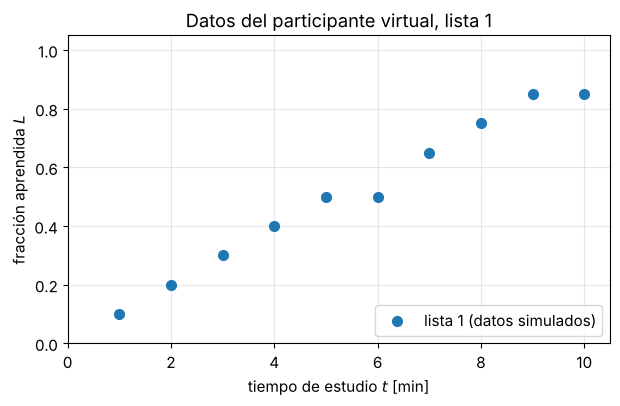

In [6]:
# Gráfica de los datos: tiempo de estudio contra fracción aprendida.
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_obs, L1, "o", ms=7, label="lista 1 (datos simulados)")
ax.set_xlim(0, 10.5)
ax.set_ylim(0, 1.05)
ax.set_xlabel("tiempo de estudio $t$ [min]")
ax.set_ylabel("fracción aprendida $L$")
ax.set_title("Datos del participante virtual, lista 1")
ax.legend(loc="lower right")
plt.show()

## 3. Estimación de $\kappa$ con la lista 1

### Método A: linealización

Como $-\ln(1-L) = \kappa t$, transformamos los datos con $y = -\ln(1 - L)$ y ajustamos una recta **que pasa por el origen**. Minimizando $\sum_i (y_i - \kappa t_i)^2$ (derivando respecto a $\kappa$ e igualando a cero) se obtiene

$$
\hat\kappa_{\text{lin}} = \frac{\sum_i t_i\, y_i}{\sum_i t_i^2}.
$$

Problema: si en alguna prueba $L = 1$, entonces $y = \infty$. Esos puntos hay que descartarlos, y además los puntos con $L$ cercano a 1 tienen muchísimo ruido después de transformarlos (un solo número de diferencia cambia mucho el logaritmo).

### Método B: mínimos cuadrados no lineales

Ajustamos directamente $L(t) = 1 - e^{-\kappa t}$ a los datos minimizando $\sum_i \big(L_i - L(t_i;\kappa)\big)^2$ con `scipy.optimize.curve_fit`. No requiere transformar los datos y usa todos los puntos.

In [7]:
def estimar_kappa_lineal(t, L):
    """
    Método A: recta por el origen en la variable transformada y = -ln(1 - L).
    Descarta las pruebas con L = 1 (su logaritmo es infinito).
    Regresa la estimación de kappa.
    """
    t, L = np.asarray(t, float), np.asarray(L, float)
    usable = L < 1                         # pruebas que sí se pueden transformar
    y = -np.log(1.0 - L[usable])
    return np.sum(t[usable] * y) / np.sum(t[usable] ** 2)


def estimar_kappa_nls(t, L):
    """
    Método B: mínimos cuadrados no lineales sobre L(t) = 1 - exp(-kappa t).
    Regresa la estimación de kappa y su error estándar aproximado
    (raíz de la varianza que reporta curve_fit).
    """
    popt, pcov = curve_fit(L_modelo, t, L, p0=[0.1], bounds=(0, np.inf))
    return popt[0], np.sqrt(pcov[0, 0])


k_lin = estimar_kappa_lineal(t_obs, L1)
k_nls, k_nls_se = estimar_kappa_nls(t_obs, L1)
print(f"Método A (linealización):           kappa = {k_lin:.3f} 1/min")
print(f"Método B (mínimos cuadrados no lin.): kappa = {k_nls:.3f} ± {k_nls_se:.3f} 1/min")

Método A (linealización):           kappa = 0.171 1/min
Método B (mínimos cuadrados no lin.): kappa = 0.148 ± 0.010 1/min


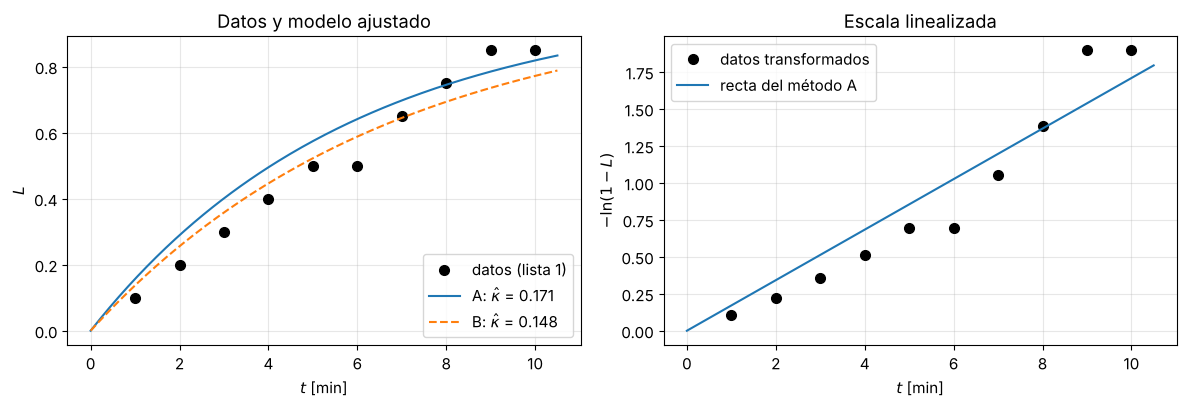

Residuos (datos - modelo B): [-0.037 -0.056 -0.058 -0.046 -0.022 -0.088  0.005  0.056  0.114  0.078]


In [8]:
# Comparamos los datos con las predicciones del modelo para ambas estimaciones.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
tt = np.linspace(0, 10.5, 200)

# Panel izquierdo: escala original.
axs[0].plot(t_obs, L1, "o", ms=7, color="k", label="datos (lista 1)")
axs[0].plot(tt, L_modelo(tt, k_lin), label=rf"A: $\hat\kappa$ = {k_lin:.3f}")
axs[0].plot(tt, L_modelo(tt, k_nls), "--", label=rf"B: $\hat\kappa$ = {k_nls:.3f}")
axs[0].set_xlabel("$t$ [min]")
axs[0].set_ylabel("$L$")
axs[0].set_title("Datos y modelo ajustado")
axs[0].legend(loc="lower right")

# Panel derecho: escala linealizada -ln(1 - L). Si el modelo es correcto,
# los puntos deben caer cerca de una recta que pasa por el origen.
usable = L1 < 1
axs[1].plot(t_obs[usable], -np.log(1 - L1[usable]), "o", ms=7, color="k",
            label="datos transformados")
axs[1].plot(tt, k_lin * tt, label="recta del método A")
axs[1].set_xlabel("$t$ [min]")
axs[1].set_ylabel(r"$-\ln(1-L)$")
axs[1].set_title("Escala linealizada")
axs[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

# Residuos: diferencia entre datos y modelo (método B). Si el modelo describe
# bien los datos, deben verse como ruido sin patrón.
residuos = L1 - L_modelo(t_obs, k_nls)
print("Residuos (datos - modelo B):", np.round(residuos, 3))

### ¿Qué tan confiable es la estimación? Un bootstrap paramétrico

Una sola sesión tiene ruido: si repitiéramos el experimento con la misma persona, obtendríamos otra $\hat\kappa$. Para cuantificar esa variabilidad usamos un **bootstrap paramétrico**: simulamos muchas sesiones con $\kappa = \hat\kappa$ (nuestra mejor estimación), estimamos $\kappa$ en cada una y vemos cómo se dispersan las estimaciones. El intervalo entre los percentiles 2.5 y 97.5 es un intervalo de confianza aproximado del 95 %.

In [9]:
def bootstrap_kappa(kappa_hat, estimador, n_rep=2000, rng=rng):
    """
    Bootstrap paramétrico: simula `n_rep` sesiones con kappa = kappa_hat,
    vuelve a estimar kappa en cada una con `estimador(t, L)` y regresa el
    arreglo de estimaciones.
    """
    t, L, _, _ = simular_sesiones(kappa_hat, n_rep=n_rep, rng=rng)
    return np.array([estimador(t, L[r]) for r in range(n_rep)])


# Para el método B el estimador regresa (kappa, error); nos quedamos con kappa.
solo_kappa_nls = lambda t, L: estimar_kappa_nls(t, L)[0]

boot_B = bootstrap_kappa(k_nls, solo_kappa_nls)
ic_B = np.percentile(boot_B, [2.5, 97.5])
print(f"Lista 1, método B: kappa = {k_nls:.3f}, IC 95% bootstrap = [{ic_B[0]:.3f}, {ic_B[1]:.3f}] 1/min")

Lista 1, método B: kappa = 0.148, IC 95% bootstrap = [0.082, 0.234] 1/min


### Ventaja de los datos simulados: ¿qué método es mejor?

Como conocemos el valor verdadero, podemos repetir **todo** el experimento miles de veces y ver cuál de los dos métodos se acerca más, en promedio, al valor real. Medimos el **sesgo** (promedio de $\hat\kappa - \kappa$) y la **dispersión** (desviación estándar de $\hat\kappa$).

Valor verdadero: kappa = 0.150

                         sesgo     desv. estándar
  A (linealización)    -0.0010     0.0382
  B (no lineal)        -0.0027     0.0382
  B sin lapsus         +0.0049     0.0425


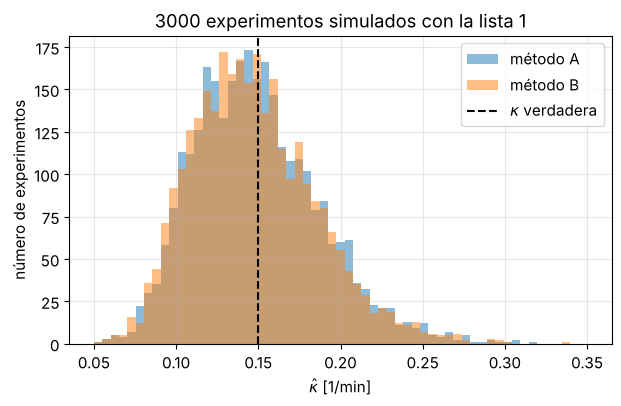

In [10]:
n_exp = 3000
k_real = KAPPA_VERDADERA[1]
t_mc, L_mc, _, _ = simular_sesiones(k_real, n_rep=n_exp)
est_A = np.array([estimar_kappa_lineal(t_mc, L_mc[r]) for r in range(n_exp)])
est_B = np.array([solo_kappa_nls(t_mc, L_mc[r]) for r in range(n_exp)])

# El mismo estudio, pero SIN lapsus, para separar el efecto del ruido que el
# modelo no contempla del efecto del método de estimación.
t_mc0, L_mc0, _, _ = simular_sesiones(k_real, n_rep=n_exp, prob_lapsus=0.0)
est_B0 = np.array([solo_kappa_nls(t_mc0, L_mc0[r]) for r in range(n_exp)])

print(f"Valor verdadero: kappa = {k_real:.3f}\n")
print("                         sesgo     desv. estándar")
for nombre, est in [("A (linealización)", est_A), ("B (no lineal)", est_B),
                    ("B sin lapsus", est_B0)]:
    print(f"  {nombre:20s} {np.mean(est) - k_real:+.4f}     {np.std(est):.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0.05, 0.35, 60)
ax.hist(est_A, bins=bins, alpha=0.5, label="método A")
ax.hist(est_B, bins=bins, alpha=0.5, label="método B")
ax.axvline(k_real, color="k", ls="--", label=r"$\kappa$ verdadera")
ax.set_xlabel(r"$\hat\kappa$ [1/min]")
ax.set_ylabel("número de experimentos")
ax.set_title(f"{n_exp} experimentos simulados con la lista 1")
ax.legend()
plt.show()

**Lectura de los resultados.**

* Los dos métodos son prácticamente **insesgados** (el sesgo es mucho menor que la dispersión) y tienen **la misma dispersión**, de unos 0.04 min⁻¹: una sola sesión de 20 números estima $\kappa$ con un error típico de alrededor del 25 %. Es bastante. Una persona que quiera conocer su $\kappa$ con precisión necesita repetir el experimento varias veces.
* Con esta cantidad de datos no hay una razón fuerte para preferir uno de los dos métodos. El método B tiene la ventaja práctica de no descartar las pruebas con $L = 1$, que con un participante más rápido serían muchas.
* Los lapsus (3 %) tampoco producen un sesgo apreciable: su efecto es pequeño comparado con el ruido del propio proceso de aprendizaje.
* **Lo más importante:** el error estándar que reportó `curve_fit` para la lista 1 (≈ 0.010) es unas cuatro veces menor que la dispersión real (≈ 0.04). La razón es que las 10 pruebas de una sesión **no son independientes**: un número aprendido en el minuto 2 sigue aprendido en los minutos 3, 4, ..., 10, así que un "golpe de suerte" temprano se arrastra a todas las pruebas siguientes. `curve_fit` supone errores independientes y por eso es demasiado optimista. Por la misma razón los residuos de la lista 1 aparecen en rachas (primero negativos, luego positivos) aunque el modelo sea el correcto. El bootstrap no tiene este problema porque simula el proceso completo.

## 4. ¿Cuánto tardaríamos en aprender listas de 20 y de 100 números?

Como el modelo nunca llega a $L = 1$, necesitamos decidir qué significa "aprender la lista". Dos criterios razonables:

**Criterio determinista.** La lista está aprendida cuando falta menos de medio número: $N(1 - L) < 1/2$, es decir $N e^{-\kappa t} < 1/2$, que da

$$
t_N = \frac{\ln(2N)}{\kappa}.
$$

**Criterio probabilista.** Con la interpretación "por número", cada número tarda un tiempo exponencial con tasa $\kappa$ en aprenderse; la lista está aprendida cuando se aprendió el **último** número. El valor esperado del máximo de $N$ exponenciales independientes es

$$
E[T_N] = \frac{1}{\kappa}\left(1 + \frac12 + \frac13 + \dots + \frac1N\right) = \frac{H_N}{\kappa} \approx \frac{\ln N + 0.577}{\kappa}.
$$

(Se ve así: con $k$ números pendientes, el siguiente se aprende tras un tiempo exponencial de tasa $k\kappa$, con media $1/(k\kappa)$; se suman esas medias para $k = N, N-1, \dots, 1$.)

Ambos criterios crecen como $\ln N$ y dan valores muy parecidos.

**La suposición clave: ¿$\kappa$ depende de la longitud de la lista?** Todo lo anterior supone que $\kappa$ es la misma para cualquier $N$. Pero $\kappa$ es una tasa *por número pendiente*: con una lista de 100 números, en un minuto de estudio le dedicamos a cada número cinco veces menos atención que con una de 20. Una alternativa razonable es suponer que lo que es constante es la **capacidad** (números aprendidos por minuto al inicio, $\kappa N$), de modo que $\kappa_N = \kappa_{20}\cdot 20/N$. Calculamos ambos escenarios.

In [11]:
from scipy.special import digamma  # H_N = digamma(N + 1) + constante de Euler


def numero_armonico(N):
    """H_N = 1 + 1/2 + ... + 1/N, calculado con la función digamma."""
    return digamma(N + 1) + np.euler_gamma


k_hat = k_nls          # nuestra estimación con la lista 1 (método B)
print(f"Usamos kappa = {k_hat:.3f} 1/min (lista 1, método B)\n")
print("                                   criterio ln(2N)/k    criterio H_N/k")
for N in [20, 100]:
    # Escenario 1: kappa no depende de N.
    t_det = np.log(2 * N) / k_hat
    t_prob = numero_armonico(N) / k_hat
    print(f"N = {N:3d}, kappa constante:           {t_det:6.1f} min          {t_prob:6.1f} min")
for N in [20, 100]:
    # Escenario 2: capacidad constante, kappa_N = kappa_20 * 20 / N.
    k_N = k_hat * 20 / N
    t_det = np.log(2 * N) / k_N
    t_prob = numero_armonico(N) / k_N
    print(f"N = {N:3d}, capacidad constante:       {t_det:6.1f} min          {t_prob:6.1f} min")

Usamos kappa = 0.148 1/min (lista 1, método B)

                                   criterio ln(2N)/k    criterio H_N/k
N =  20, kappa constante:             25.0 min            24.3 min
N = 100, kappa constante:             35.8 min            35.1 min
N =  20, capacidad constante:         25.0 min            24.3 min
N = 100, capacidad constante:        179.2 min           175.5 min


Comprobamos con la simulación el criterio probabilista: simulamos muchas veces el tiempo (en minutos de estudio) que tarda el participante en tener **todos** los números aprendidos. Como en la simulación el aprendizaje ocurre en rondas de un minuto, esperamos valores un poco mayores que $H_N/\kappa$ (redondeo hacia arriba al minuto siguiente).

N = 20                          : media simulada =   24.9 min,  H_N/kappa =   24.3 min


N = 100, kappa constante        : media simulada =   35.7 min,  H_N/kappa =   35.1 min
N = 100, capacidad constante    : media simulada =  175.9 min,  H_N/kappa =  175.5 min


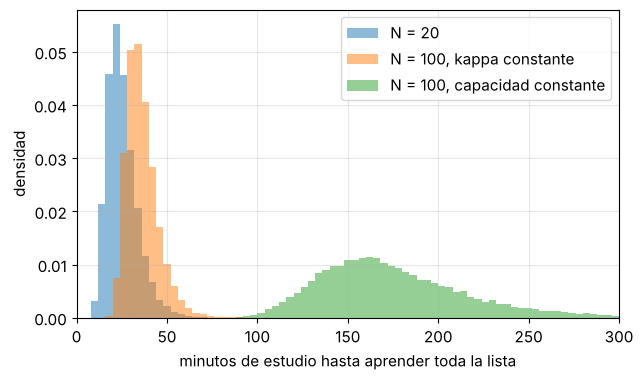

In [12]:
def minutos_para_aprender_todo(kappa, N, n_rep=20000, rng=rng):
    """
    Minutos de estudio hasta que los N números están aprendidos, en el
    participante virtual (sin contar lapsus): el máximo de N geométricas.
    """
    p = 1.0 - np.exp(-kappa * DT)
    return rng.geometric(p, size=(n_rep, N)).max(axis=1) * DT


fig, ax = plt.subplots(figsize=(7, 4))
for N, kN, etiqueta in [(20, k_hat, "N = 20"),
                        (100, k_hat, "N = 100, kappa constante"),
                        (100, k_hat * 20 / 100, "N = 100, capacidad constante")]:
    T = minutos_para_aprender_todo(kN, N)
    print(f"{etiqueta:32s}: media simulada = {T.mean():6.1f} min,  H_N/kappa = {numero_armonico(N) / kN:6.1f} min")
    ax.hist(T, bins=np.arange(0, 400, 4), alpha=0.5, density=True, label=etiqueta)
ax.set_xlim(0, 300)
ax.set_xlabel("minutos de estudio hasta aprender toda la lista")
ax.set_ylabel("densidad")
ax.legend()
plt.show()

**Respuesta.** Con $\hat\kappa$ de la lista 1, una lista de 20 números requiere del orden de 20 a 25 minutos de estudio. Para 100 números la respuesta **depende de una suposición que nuestro experimento no puede verificar**: si $\kappa$ no dependiera de $N$, bastaría con unos 10 minutos más (el crecimiento es solo logarítmico); si lo constante es la capacidad, se necesitan unas tres horas. La segunda opción es mucho más creíble (nadie aprende 100 números casi tan rápido como 20), pero para distinguirlas habría que hacer el experimento con listas de distintas longitudes. Es un buen ejemplo de que **extrapolar un modelo fuera de las condiciones del experimento exige suposiciones adicionales**.

Además, las distribuciones de la figura son anchas y sesgadas a la derecha: el último número suele resistirse. Por eso el promedio no cuenta toda la historia.

## 5. Listas 2, 3 y 4: ¿$\kappa$ es constante o mejora con la práctica?

Repetimos el protocolo con las otras listas (el enunciado dice "las otras dos listas", pero hay tres más; usamos las tres). Para cada lista estimamos $\kappa$ con el método B y su intervalo bootstrap.

In [13]:
resultados = {}   # lista -> (t, L, kappa_hat, ic_inf, ic_sup)
L_listas = {1: L1}
for j in [2, 3, 4]:
    # Nueva sesión con la kappa (oculta) del participante para esa lista.
    t_j, L_sim_j, _, _ = simular_sesiones(KAPPA_VERDADERA[j], n_rep=1)
    L_listas[j] = L_sim_j[0]

for j in LISTAS:
    k_j, _ = estimar_kappa_nls(t_obs, L_listas[j])
    boot = bootstrap_kappa(k_j, solo_kappa_nls)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    resultados[j] = (k_j, lo, hi)
    print(f"Lista {j}: L = {np.round(L_listas[j], 2)}")
    print(f"         kappa = {k_j:.3f} 1/min, IC 95% = [{lo:.3f}, {hi:.3f}]")

Lista 1: L = [0.1  0.2  0.3  0.4  0.5  0.5  0.65 0.75 0.85 0.85]
         kappa = 0.148 1/min, IC 95% = [0.084, 0.235]


Lista 2: L = [0.15 0.3  0.45 0.65 0.6  0.7  0.75 0.75 0.8  0.7 ]
         kappa = 0.187 1/min, IC 95% = [0.108, 0.293]


Lista 3: L = [0.3  0.35 0.5  0.65 0.7  0.65 0.65 0.7  0.85 0.85]
         kappa = 0.204 1/min, IC 95% = [0.118, 0.318]


Lista 4: L = [0.1  0.4  0.45 0.5  0.65 0.9  0.9  0.9  0.95 0.9 ]
         kappa = 0.241 1/min, IC 95% = [0.141, 0.365]


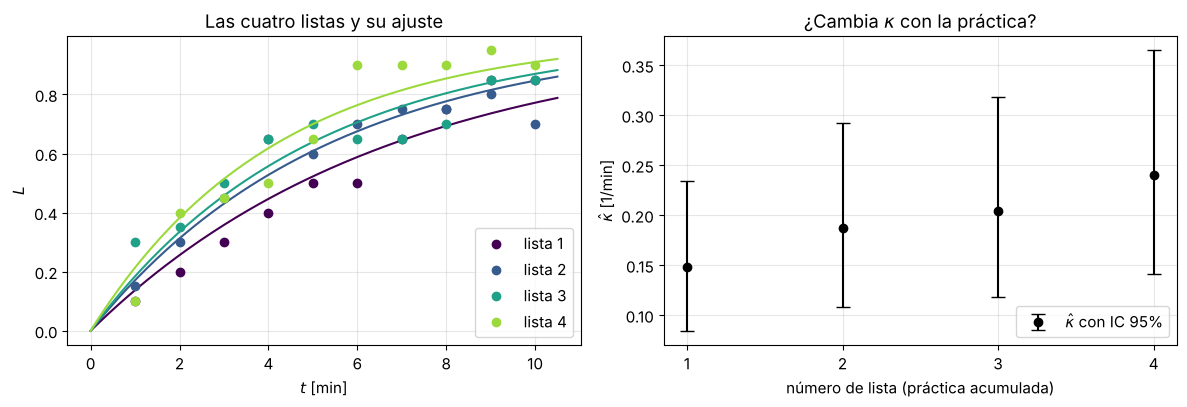

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
colores = plt.cm.viridis(np.linspace(0, 0.85, 4))

# Panel izquierdo: datos y ajuste de cada lista.
for j, c in zip(LISTAS, colores):
    axs[0].plot(t_obs, L_listas[j], "o", color=c, label=f"lista {j}")
    axs[0].plot(tt, L_modelo(tt, resultados[j][0]), color=c)
axs[0].set_xlabel("$t$ [min]")
axs[0].set_ylabel("$L$")
axs[0].set_title("Las cuatro listas y su ajuste")
axs[0].legend(loc="lower right")

# Panel derecho: kappa estimada (con su IC) contra el número de lista.
js = np.array(list(LISTAS))
k_est = np.array([resultados[j][0] for j in js])
err = np.array([[resultados[j][0] - resultados[j][1], resultados[j][2] - resultados[j][0]] for j in js]).T
axs[1].errorbar(js, k_est, yerr=err, fmt="o", capsize=5, color="k", label=r"$\hat\kappa$ con IC 95%")
axs[1].set_xticks(js)
axs[1].set_xlabel("número de lista (práctica acumulada)")
axs[1].set_ylabel(r"$\hat\kappa$ [1/min]")
axs[1].set_title(r"¿Cambia $\kappa$ con la práctica?")
axs[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

### Una prueba de hipótesis por simulación

Mirar los intervalos es útil, pero queremos una respuesta más precisa a "¿$\kappa$ es constante?". Usamos como estadístico la **pendiente** $b$ de la recta que mejor ajusta $\hat\kappa_j$ contra $j$. Bajo la hipótesis nula ($\kappa$ es la misma en las cuatro listas) esperamos $b \approx 0$, pero no exactamente cero por el ruido. ¿Qué tan grande puede ser $b$ solo por azar? Lo averiguamos simulando:

1. Estimamos un $\kappa$ común con las cuatro listas juntas.
2. Simulamos muchas veces las cuatro sesiones con ese $\kappa$ común, estimamos las cuatro $\hat\kappa_j$ y su pendiente.
3. El valor $p$ es la fracción de simulaciones con una pendiente al menos tan grande como la observada.

kappa común (hipótesis nula) = 0.191 1/min
pendiente observada          = +0.0295 (1/min) por lista
valor p (una cola)           = 0.0845


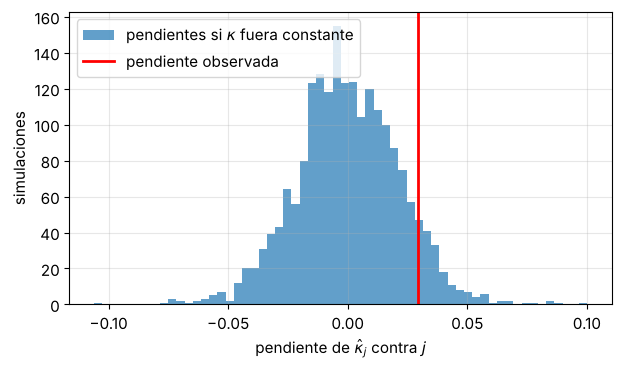

In [15]:
def pendiente(js, ks):
    """Pendiente de la recta de mínimos cuadrados de ks contra js."""
    return np.polyfit(js, ks, deg=1)[0]


b_obs = pendiente(js, k_est)

# 1) kappa común: ajustamos el modelo a los 40 puntos de las cuatro listas a la vez.
t_todos = np.tile(t_obs, 4)
L_todos = np.concatenate([L_listas[j] for j in js])
k_comun, _ = estimar_kappa_nls(t_todos, L_todos)

# 2) simulaciones bajo la hipótesis nula.
n_sim = 2000
b_nula = np.empty(n_sim)
for s in range(n_sim):
    _, L_null, _, _ = simular_sesiones(k_comun, n_rep=4)   # cuatro listas
    ks_null = [solo_kappa_nls(t_obs, L_null[r]) for r in range(4)]
    b_nula[s] = pendiente(js, ks_null)

# 3) valor p (de una cola: nos interesa si MEJORA con la práctica).
p_valor = np.mean(b_nula >= b_obs)
print(f"kappa común (hipótesis nula) = {k_comun:.3f} 1/min")
print(f"pendiente observada          = {b_obs:+.4f} (1/min) por lista")
print(f"valor p (una cola)           = {p_valor:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(b_nula, bins=60, alpha=0.7, label=r"pendientes si $\kappa$ fuera constante")
ax.axvline(b_obs, color="r", lw=2, label="pendiente observada")
ax.set_xlabel("pendiente de $\\hat\\kappa_j$ contra $j$")
ax.set_ylabel("simulaciones")
ax.legend()
plt.show()

**Interpretación.** Las cuatro estimaciones aumentan de una lista a otra, pero el valor $p$ es de alrededor de 0.08: con un nivel de significancia del 5 % **no podemos afirmar** que $\kappa$ mejora con la práctica. Y sin embargo sabemos que el participante virtual sí mejora (su $\kappa$ pasa de 0.15 a 0.27). No hay contradicción: no rechazar la hipótesis nula no significa que sea cierta, sino que **los datos no alcanzan** para distinguir el efecto del ruido.

¿Qué tan probable era detectar la mejora con este diseño? Eso es la **potencia** de la prueba. La estimamos simulando muchas veces el experimento completo con las $\kappa_j$ verdaderas y contando en qué fracción de ellos la pendiente supera el valor crítico (el percentil 95 de la distribución nula). También vemos cómo cambia la potencia si cada lista se estudiara en varias sesiones independientes (por ejemplo, en días distintos y con listas nuevas del mismo tipo); para cada diseño recalculamos el valor crítico.

In [16]:
def pendientes_simuladas(kappas, n_sesiones_por_lista, n_sim=1000):
    """
    Simula `n_sim` experimentos completos (cuatro listas, con
    `n_sesiones_por_lista` sesiones cada una) usando las tasas `kappas`
    (un valor por lista) y regresa la pendiente de kappa_j estimada contra j
    en cada experimento. Si hay varias sesiones por lista, kappa_j se estima
    ajustando todas las sesiones de esa lista juntas.
    """
    b = np.empty(n_sim)
    for s in range(n_sim):
        ks = []
        for k_j in kappas:
            t_s, L_s, _, _ = simular_sesiones(k_j, n_rep=n_sesiones_por_lista)
            ks.append(solo_kappa_nls(np.tile(t_s, n_sesiones_por_lista), L_s.ravel()))
        b[s] = pendiente(js, ks)
    return b


def potencia(n_sesiones_por_lista, n_sim=1000):
    """
    Potencia de la prueba de la pendiente para un diseño dado:
      1. valor crítico = percentil 95 de las pendientes si kappa fuera
         constante (igual a la kappa común) con ESE diseño;
      2. potencia = fracción de experimentos con las kappa VERDADERAS (que sí
         mejoran) cuya pendiente supera ese valor crítico.
    """
    b_nula_diseno = pendientes_simuladas([k_comun] * 4, n_sesiones_por_lista, n_sim)
    b_critico = np.percentile(b_nula_diseno, 95)
    b_real = pendientes_simuladas([KAPPA_VERDADERA[j] for j in js], n_sesiones_por_lista, n_sim)
    return np.mean(b_real > b_critico)


for n_ses in [1, 3, 5]:
    print(f"{n_ses} sesión(es) por lista: potencia ≈ {potencia(n_ses):.2f}")

1 sesión(es) por lista: potencia ≈ 0.45


3 sesión(es) por lista: potencia ≈ 0.91


5 sesión(es) por lista: potencia ≈ 0.98


Con una sola sesión por lista, la prueba detecta la mejora real en menos de la mitad de los experimentos: nuestro resultado ($p \approx 0.08$) es justo lo que cabía esperar. Con tres sesiones por lista la potencia sube a cerca del 90 %, y con cinco a casi 100 %. Moraleja: **antes de hacer un experimento conviene simular si su diseño es capaz de detectar el efecto que buscamos.**

### ¿Cómo modificar el modelo para incluir la práctica?

Si $\kappa$ mejora con la práctica, deja de ser una constante y se vuelve una función de la **práctica acumulada** $P$ (minutos estudiados antes de empezar la lista). Una forma sencilla, que crece y luego se satura (no podemos mejorar indefinidamente), es

$$
\frac{dL}{dt} = \kappa(P)\,(1 - L), \qquad \kappa(P) = \kappa_{\max} - (\kappa_{\max} - \kappa_0)\,e^{-P/P_0},
$$

donde $\kappa_0$ es la tasa de un principiante, $\kappa_{\max}$ la tasa de un experto y $P_0$ cuánta práctica se necesita para notar la mejora. Si la práctica también ocurre *durante* la lista, $P$ crece con $t$ y el sistema se convierte en dos ecuaciones acopladas:

$$
\frac{dL}{dt} = \kappa\,(1 - L), \qquad \frac{d\kappa}{dt} = \eta\,(\kappa_{\max} - \kappa).
$$

Otras modificaciones naturales, que con datos reales valdría la pena considerar:

* **Olvido:** $\dfrac{dL}{dt} = \kappa(1 - L) - \varphi L$. Ahora $L$ tiende a $\kappa/(\kappa + \varphi) < 1$: el aprendizaje se estanca antes de llegar a la lista completa.
* **Dependencia de la longitud:** $\kappa = c/N$ (la capacidad $c$ se reparte entre los $N$ números), como discutimos en la sección 4.

Ajustamos la primera modificación a nuestras cuatro estimaciones. Antes de la lista $j$ se acumularon $P_j = 10\,(j - 1)$ minutos de práctica. Con solo cuatro puntos y tres parámetros, el ajuste es muy incierto; lo hacemos para ilustrar el procedimiento, no para creer ciegamente en los números.

Ajuste: kappa_0 = 0.149, kappa_max = 0.462, P_0 = 90.4 min
Errores estándar aproximados (k0, kmax, P0): [3.800000e-02 4.034000e+00 1.355076e+03]


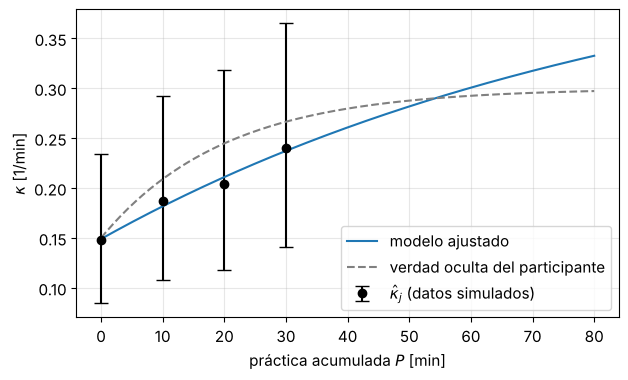

In [17]:
def kappa_practica(P, k0, kmax, P0):
    """Tasa de memorización como función de la práctica acumulada P (min)."""
    return kmax - (kmax - k0) * np.exp(-P / P0)


P_j = 10.0 * (js - 1)    # minutos de práctica antes de cada lista: 0, 10, 20, 30
sigma = (err[0] + err[1]) / 2 / 1.96   # error estándar aproximado de cada kappa_j
popt, pcov = curve_fit(kappa_practica, P_j, k_est, p0=[0.15, 0.3, 20],
                       sigma=sigma, absolute_sigma=True,
                       bounds=([0, 0, 1], [1, 1, 500]))
k0_hat, kmax_hat, P0_hat = popt
print(f"Ajuste: kappa_0 = {k0_hat:.3f}, kappa_max = {kmax_hat:.3f}, P_0 = {P0_hat:.1f} min")
print("Errores estándar aproximados (k0, kmax, P0):", np.round(np.sqrt(np.diag(pcov)), 3))
# Errores enormes en kappa_max y P_0 indican que, con cuatro puntos, esos dos
# parámetros NO son identificables: muchas combinaciones ajustan igual de bien.

PP = np.linspace(0, 80, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(P_j, k_est, yerr=err, fmt="o", capsize=5, color="k", label=r"$\hat\kappa_j$ (datos simulados)")
ax.plot(PP, kappa_practica(PP, *popt), label="modelo ajustado")
ax.plot(PP, kappa_practica(PP, KAPPA_0, KAPPA_MAX, 10 * TAU), "--", color="gray",
        label="verdad oculta del participante")
ax.set_xlabel("práctica acumulada $P$ [min]")
ax.set_ylabel(r"$\kappa$ [1/min]")
ax.legend(loc="lower right")
plt.show()

## 6. Revelamos la verdad oculta

Comparamos lo que estimamos con los valores que le dimos al participante virtual.

In [18]:
print(" lista | kappa verdadera | kappa estimada | IC 95%           | ¿IC contiene la verdad?")
for j in js:
    k_j, lo, hi = resultados[j]
    dentro = "sí" if lo <= KAPPA_VERDADERA[j] <= hi else "no"
    print(f"   {j}   |      {KAPPA_VERDADERA[j]:.3f}      |     {k_j:.3f}      | [{lo:.3f}, {hi:.3f}] |  {dentro}")

 lista | kappa verdadera | kappa estimada | IC 95%           | ¿IC contiene la verdad?
   1   |      0.150      |     0.148      | [0.084, 0.235] |  sí
   2   |      0.209      |     0.187      | [0.108, 0.293] |  sí
   3   |      0.245      |     0.204      | [0.118, 0.318] |  sí
   4   |      0.267      |     0.241      | [0.141, 0.365] |  sí


## Conclusiones

1. El modelo $dL/dt = \kappa(1-L)$ tiene solución $L = 1 - e^{-\kappa t}$ y puede verse como el promedio de un proceso en el que cada número se aprende en un tiempo aleatorio exponencial.
2. Con una sola lista de 20 números y 10 pruebas, $\kappa$ se estima con una incertidumbre de alrededor del 25 %. La linealización y el ajuste no lineal funcionan igual de bien aquí, pero el error estándar "de libro" de `curve_fit` subestima mucho la incertidumbre porque las pruebas de una sesión no son independientes; el bootstrap paramétrico da una medida honesta.
3. El tiempo para aprender una lista crece como $\ln N/\kappa$ **si** $\kappa$ no depende de $N$. Para extrapolar a 100 números hay que decidir cómo cambia $\kappa$ con la longitud de la lista, algo que este experimento no puede responder.
4. Para detectar el efecto de la práctica conviene una prueba formal (aquí, por simulación), porque las diferencias entre listas son del mismo orden que el ruido de cada estimación. En nuestra simulación la mejora es real, pero una sesión por lista no basta para demostrarla con significancia del 5 %: el diseño del experimento tiene poca potencia. El modelo se extiende haciendo que $\kappa$ dependa de la práctica acumulada.

**¿Y con datos reales?** Con el participante virtual, el modelo es cierto por construcción (salvo los lapsus), así que los ajustes se ven bien. Con datos reales esperaríamos desviaciones que vale la pena buscar en los residuos: un estancamiento por debajo de $L = 1$ (olvido o fatiga), un arranque lento (los primeros minutos sirven para "organizar" la lista), efectos de posición (los primeros y últimos números de la lista se recuerdan mejor) e interferencia o ayuda entre listas que comparten números, como vimos al inicio. Si haces el experimento tú, puedes reemplazar los datos simulados por los tuyos: basta con sustituir `L1` y `L_listas` por tus fracciones observadas.